# Week6_ex2_analysis — SLG fault levels when the transformer winding connections are unknown

Deep dive. A single line-to-ground fault drives the three sequence networks in series,

$$I_F = 3 I_0 = \frac{3\,V_F}{Z_1 + Z_2 + Z_0},$$

and $Z_0$ is set almost entirely by the transformer windings: a grounded-wye/grounded-wye unit passes zero-sequence current between its two buses, a delta/grounded-wye unit grounds its wye side and isolates the delta side, and a delta/delta unit blocks both. All 14 transformers of the Problem 10.64 case are entered as "Unknown", which PowerWorld leaves out of the zero sequence altogether. Public network data (benchmark cases, MATPOWER files) usually carry no winding information either, so this notebook measures how much the answer depends on that assumption and how to reproduce it with `calc_sc`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.shortcircuit as sc
from scipy.linalg import LinAlgWarning
from case37 import S_BASE, BUSES, build_case, solve_pw
from fault37 import ORDER, KV, slg_results, slg_at, build_sc_case

# 1. FutureWarning from pandas inside pandapower's branch builder; it prints the local install path
warnings.filterwarnings("ignore", category=FutureWarning)

net = solve_pw(build_case(), numba=False)
names = dict((b, n) for b, n, _ in BUSES)

# 2. Three readings of "Unknown": left out (PowerWorld), grounded wye on both sides (R0 + jX0 in
#    series), delta on the low-voltage side with the high-voltage side grounded (R0 + jX0 to ground)
ASSUMPTIONS = {"open": "Open (PowerWorld)", "series": "YNyn", "ground_hv": "YNd, hv grounded"}
i_slg = pd.DataFrame({label: slg_results(net, key)["I [pu]"] for key, label in ASSUMPTIONS.items()})
i_slg.insert(0, "kV", [KV[b] for b in ORDER])
i_slg.insert(0, "Name", [names[b] for b in ORDER])
i_slg.round(3)

,Name,kV,Open (PowerWorld),YNyn,"YNd, hv grounded"
bus,,,,,
1,OAK345,345.0,21.989,25.616,29.913
3,ASH138,138.0,5.635,15.565,17.319
5,POPLAR69,69.0,8.272,8.762,8.272
10,PINE69,69.0,6.048,16.594,6.048
12,OAK69,69.0,10.285,19.750,10.285
13,PALM69,69.0,5.512,7.987,5.512
14,REDBUD69,69.0,8.866,8.954,8.866
15,PECAN69,69.0,27.259,31.210,27.259
16,ORANGE69,69.0,15.121,17.260,15.121


## Hypothesis 1

The winding assumption only rescales the result: every bus should see roughly the same ratio between the YNyn or YNd current and the PowerWorld (open) current.

In [2]:
# 3. Ratio to the PowerWorld assumption, summarized per voltage level
ratio = i_slg[["YNyn", "YNd, hv grounded"]].div(i_slg["Open (PowerWorld)"], axis=0)
ratio.insert(0, "kV", i_slg.kV)
h1 = ratio.groupby("kV").agg(["min", "max"])
h1.index = h1.index.astype(int)
h1.sort_index(ascending=False).round(3)

YNyn        YNd, hv grounded       
       min    max              min    max
kV                                       
345  1.020  1.165            1.095  1.449
138  1.212  5.483            1.306  5.268
69   1.010  2.744            1.000  1.000

**Verdict: rejected.** The ratio ranges over a factor of five and depends on the voltage level. The 138 kV buses, whose only zero-sequence source in the PowerWorld model is the PEAR138 unit, rise by a factor of 1.2–5.5 under YNyn and 1.3–5.3 under YNd (ELM138: 5.4 → 29.9 pu). The 69 kV buses rise by 1–174% under YNyn (PINE69 most, next to two 69/138 kV transformers) and do not change at all under YNd, because a delta winding on the 69 kV side keeps them isolated exactly as before. The 345 kV buses, already grounded by three large units, move by 2–45%. No single correction factor converts one assumption into another.

## Hypothesis 2

Leaving the transformers out gives the lowest SLG current at every bus: any winding that grounds or connects a voltage level can only add zero-sequence paths, so $|Z_0|$ can only fall.

In [3]:
# 4. Smallest ratio over all buses for each alternative assumption
h2 = pd.DataFrame({"Min ratio": ratio[["YNyn", "YNd, hv grounded"]].min(),
                   "Bus at min": ratio[["YNyn", "YNd, hv grounded"]].idxmin().map(names)})
assert (h2["Min ratio"] >= 1 - 1e-9).all()
h2.round(4)

,Min ratio,Bus at min
YNyn,1.0099,REDBUD69
"YNd, hv grounded",1.0000,POPLAR69


**Verdict: accepted.** No bus loses current under either alternative; the smallest ratio is exactly 1 (69 kV buses under YNd). The PowerWorld default is therefore the lower bound. That makes it the right case for protection *sensitivity* (will a ground relay still pick up the weakest fault?) and the wrong case for breaker *duty*, where it understates the 138 kV current by a factor of up to 5.5.

## Hypothesis 3

The Problem 10.64 answer — the share of buses that sag below 0.75 pu during the ORANGE69 SLG fault (16 of 37 with PowerWorld) — does not depend on the winding assumption, since ORANGE69 is a 69 kV bus fed mostly by 69 kV generators.

In [4]:
# 5. Lowest phase voltage at every bus during the ORANGE69 fault, for each assumption
low = pd.DataFrame({label: slg_at(net, 16, key)[1].abs().min(axis=1) for key, label in ASSUMPTIONS.items()})
h3 = pd.DataFrame({"I_F ORANGE69 [pu]": [abs(slg_at(net, 16, k)[0]) for k in ASSUMPTIONS],
                   "Buses < 0.75 pu": (low < 0.75).sum().values,
                   "Share [%]": 100 * (low < 0.75).sum().values / len(low)}, index=list(ASSUMPTIONS.values()))
base = low["Open (PowerWorld)"] < 0.75
h3["Buses added vs open"] = [", ".join(names[b] for b in low.index[(low[c] < 0.75) & ~base]) or "-"
                             for c in low.columns]
h3["Buses removed vs open"] = [", ".join(names[b] for b in low.index[(low[c] >= 0.75) & base]) or "-"
                               for c in low.columns]
h3.round(3)

,I_F ORANGE69 [pu],Buses < 0.75 pu,Share [%],Buses added vs open,Buses removed vs open
Open (PowerWorld),15.121,16,43.243,-,-
YNyn,17.260,19,51.351,"ASH138, OAK138, CEDAR138, PEAR138",PINE69
"YNd, hv grounded",15.121,16,43.243,-,-


**Verdict: rejected.** Under YNyn the fault current at ORANGE69 rises from 15.1 to 17.3 pu and the list itself changes: four 138 kV buses (ASH138, OAK138, CEDAR138, PEAR138) now sag below 0.75 pu because the zero-sequence voltage reaches them through the transformers, while PINE69 recovers from 0.547 to 0.752 pu. The share goes from 43% to 51%. YNd leaves the answer unchanged because it keeps the 69 kV zero-sequence network exactly as PowerWorld has it. A voltage-sag statistic is only as good as the winding data behind it.

## Hypothesis 4

`calc_sc(fault="1ph")` can reproduce the PowerWorld assumption when every transformer is entered with vector group `Dd` (zero sequence blocked on both sides) and every in-service generator gets a compensated YNd grounding bank, as found on the Example 10.8 system. Without the banks it should fail badly, because all nine units are grounded generators connected directly to network buses.

In [5]:
def calc_sc_slg(banks):
    # 6. IEC 60909 max SLG current [pu on each bus's own base]; the empty delta-side bus of a
    #    grounding bank makes the zero-sequence Ybus ill-conditioned (scipy warns and prints its
    #    install path), but that row never reaches the real buses
    n = build_sc_case(banks)
    pp.runpp(n, numba=False)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=LinAlgWarning)
        sc.calc_sc(n, fault="1ph", case="max")
    return n.res_bus_sc.ikss_ka.loc[ORDER] / [S_BASE / (np.sqrt(3) * KV[b]) for b in ORDER]

h4 = pd.DataFrame({"kV": i_slg.kV, "Classical [pu]": i_slg["Open (PowerWorld)"],
                   "calc_sc, no banks [pu]": calc_sc_slg(False).values,
                   "calc_sc, banks [pu]": calc_sc_slg(True).values})
h4["No banks dev [%]"] = (h4["calc_sc, no banks [pu]"] / h4["Classical [pu]"] - 1) * 100
h4["Banks dev [%]"] = (h4["calc_sc, banks [pu]"] / h4["Classical [pu]"] - 1) * 100
h4_summary = h4.groupby("kV")[["No banks dev [%]", "Banks dev [%]"]].agg(["min", "max"])
h4_summary.index = h4_summary.index.astype(int)
h4_summary.sort_index(ascending=False).round(2)

No banks dev [%]        Banks dev [%]      
                 min    max           min   max
kV                                             
345           -95.03 -89.49          5.20  6.52
138           -95.68 -73.21          7.07  9.48
69            -94.82 -63.16          6.47  9.80

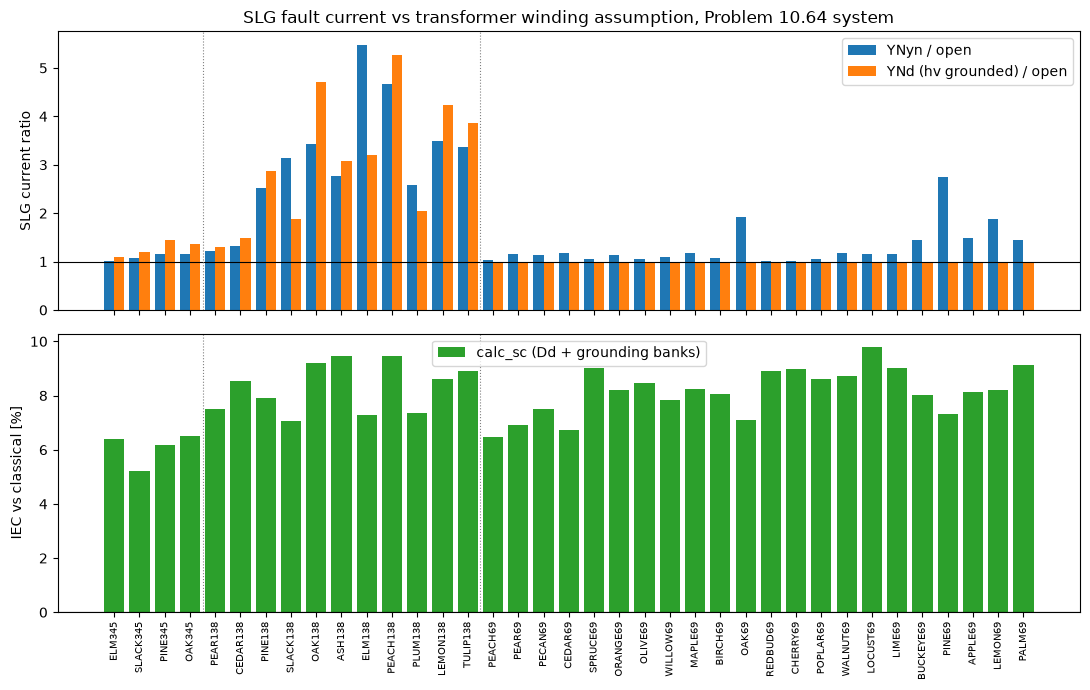

In [6]:
# 7. Bus-by-bus view of both effects, buses grouped by voltage level
order = i_slg.sort_values(["kV", "Open (PowerWorld)"], ascending=[False, False]).index
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
x = np.arange(len(order))
ax1.bar(x - 0.2, ratio.loc[order, "YNyn"], 0.4, label="YNyn / open")
ax1.bar(x + 0.2, ratio.loc[order, "YNd, hv grounded"], 0.4, label="YNd (hv grounded) / open")
ax1.axhline(1, color="black", lw=0.8)
ax1.set_ylabel("SLG current ratio")
ax1.set_title("SLG fault current vs transformer winding assumption, Problem 10.64 system")
ax1.legend()
ax2.bar(x, h4.loc[order, "Banks dev [%]"], color="tab:green", label="calc_sc (Dd + grounding banks)")
ax2.axhline(0, color="black", lw=0.8)
ax2.set_ylabel("IEC vs classical [%]")
ax2.legend()
ax2.set_xticks(x, [f"{names[b]}" for b in order], rotation=90, fontsize=7)
for ax in (ax1, ax2):
    for edge in np.flatnonzero(np.diff(i_slg.loc[order, "kV"].to_numpy())) + 0.5:
        ax.axvline(edge, color="grey", ls=":", lw=0.8)
plt.tight_layout()
plt.savefig("Images/Week6_ex2_slg_winding_assumption.png", dpi=150, bbox_inches="tight")
plt.show()

**Verdict: accepted.** With `Dd` transformers and the eight grounding banks, `calc_sc` lands 5.2–9.8% above the classical result at all 37 buses — the expected IEC margin from $c_{max} = 1.1$ against pre-fault voltages near 1.0 pu, partly offset by $K_G$ and $K_T$. Without the banks the only zero-sequence path left is line charging, and the current collapses to 1.2–2.3 pu, 63–96% below the classical value at every bus. On this system the IEC result stays above the classical one everywhere, unlike the Example 10.8 system, so the per-system check remains necessary.

## Final conclusion

- PowerWorld's "Unknown" winding connection removes the transformer from the zero sequence; in pandapower that is vector group `Dd`.
- The assumption matters, and not uniformly: on this system the 138 kV SLG currents change by up to a factor of 5.5 while the 69 kV buses do not change at all under YNd.
- Leaving the windings open is the lower bound of every SLG current. The voltage-sag answer moves too: 16 buses (43%) below 0.75 pu with open windings, 19 (51%) under YNyn, with a different set of buses.
- `calc_sc` reproduces the open-winding case only with a grounding bank for every grounded generator; without them it reports only 4–37% of the classical current.

**Rules for the project (unknown winding data):**
1. Run SLG studies under at least two assumptions — all transformers open (`Dd`, lower bound) and all YNyn (upper bound for most buses) — and report the range, not a single number.
2. Breaker duty: take the highest current over the assumptions. Ground-relay sensitivity and minimum-fault checks: take the open case.
3. Voltage-sag statistics (share of buses below a threshold) are reported with the assumption they were computed under.
4. In `calc_sc`, give every grounded generator a compensated grounding bank, whatever the transformer assumption.